# Лабораторная работа №5. Дифференциальное кодирование изображений

**Цель работы** — сравнить точность четырёх предсказателей ДИКМ и проверить,
как один ошибочный бит влияет на восстановленное изображение.

В ДИКМ кодируется разность между исходной яркостью $x$ и предсказанием $p$.
Индекс квантованной разности занимает меньше бит, чем исходная яркость.
Декодер рассчитывает то же предсказание и прибавляет к нему квантованную разность
$f_q$. Кодер ведёт собственную копию восстановленного кадра, поэтому оба
предсказателя используют одинаковых соседей при передаче без ошибок.

## 1. Исходные данные и правила обхода

In [1]:
from bisect import bisect_right
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from PIL import Image

IMAGE_PATH = Path('content') / '04_boat.tif'
with Image.open(IMAGE_PATH) as image:
    source = np.asarray(image.convert('L'))
height, width = source.shape
assert min(source.shape) >= 2 and source.size >= 4
print(f'{IMAGE_PATH.as_posix()}, {width}×{height}, {source.dtype}, '
      f'яркость {source.min()}–{source.max()}, исходный растр {source.nbytes:,} байт')

PREDICTORS = {
    'П-1': (1., 0., 0., 0.),
    'П-2': (.5, .5, 0., 0.),
    'П-3': (.25, .25, .25, .25),
    'П-4': (1., 1., -1., 0.),
}
RATES = {2: 4, 4: 2, 8: 1}

content/04_boat.tif, 512×512, uint8, яркость 0–239, исходный растр 262,144 байт


### Предсказатели и границы

Пиксели обходятся строка за строкой слева направо. Вектор коэффициентов
применяется к уже восстановленным соседям $(L,U,UL,UR)$, где $L$ — слева,
$U$ — сверху, $UL$ — сверху слева, $UR$ — сверху справа. Верхняя строка
уже обработана целиком, поэтому $UR$ доступен.

| Предсказатель | Оценка во внутренней области | Какие участки описывает |
|---|---|---|
| П-1 | $L$ | Участки, где яркость меняется плавно вдоль строки. |
| П-2 | $(L+U)/2$ | Участки с похожими яркостями слева и сверху. |
| П-3 | $(L+U+UL+UR)/4$ | Локальный средний уровень в окрестности. |
| П-4 | $L+U-UL$ | Локальную плоскость яркости. У резкой границы возможен большой промах. |

Для первого пикселя начальная оценка равна 0. В верхней строке берётся
пиксель слева, в первом столбце — сверху. На правой границе недоступный
$UR$ заменяется на $U$. Эти правила одинаковы для кодера и декодера.
После прибавления квантованной разности восстановленная яркость
ограничивается диапазоном 0–255. В обратной связи сохраняется вещественное
значение без дополнительного округления.

In [2]:
def predict(frame, row, col, width, coefficients):
    if row == 0:
        return frame[0][col - 1] if col else 0.
    if col == 0:
        return frame[row - 1][0]
    left = frame[row][col - 1]
    up = frame[row - 1][col]
    up_left = frame[row - 1][col - 1]
    up_right = frame[row - 1][min(col + 1, width - 1)]
    a1, a2, a3, a4 = coefficients
    return a1 * left + a2 * up + a3 * up_left + a4 * up_right


def restore_sample(prediction, level):
    return min(255., max(0., prediction + level))

## 2. Построение шкалы Ллойда — Макса

Разностный сигнал моделируется симметричным распределением Лапласа
$W(f)=\exp(-|f|/s)/(2s)$. Масштаб $s$ оценивается как средний модуль
предварительного остатка на исходном кадре для каждого предсказателя.
Эта оценка нужна один раз для построения шкалы и фиксируется для всех
трёх скоростей. При дальнейшем кодировании и декодировании рекурсия
использует восстановленные значения.

Сначала строится положительная половина шкалы для единичного масштаба.
Шаг Ллойда — Макса заново вычисляет уровень как условное среднее в интервале,
затем сдвигает границы в середины между уровнями. Крайний интервал
неограничен сверху. Для единичной экспоненты положительный интервал
$[a,a+d)$ имеет условное среднее $a+1-d/(\exp(d)-1)$, а интервал
$[a,+\infty)$ — $a+1$. После сходимости уровни отражаются относительно нуля
и умножаются на $s$. При одном бите уровни равны $-s$ и $+s$, порог равен нулю.

In [3]:
def estimate_scale(image, coefficients):
    rows = image.astype(float).tolist()
    height, width = image.shape
    total = 0.
    for row in range(height):
        for col in range(width):
            total += abs(rows[row][col] - predict(rows, row, col, width, coefficients))
    return max(total / image.size, 1e-6)


def lloyd_max_unit(bits, tolerance=1e-10, limit=10000):
    intervals = 2**(bits - 1)
    lower = np.linspace(0., 8., intervals + 1)[:-1]
    for iteration in range(1, limit + 1):
        positive = lower + 1
        widths = np.diff(lower)
        positive[:-1] -= widths / np.expm1(widths)

        updated = np.r_[0., (positive[:-1] + positive[1:]) / 2]
        if np.max(np.abs(updated - lower)) < tolerance:
            levels = np.r_[-positive[::-1], positive]
            return levels, iteration
        lower = updated
    raise RuntimeError('Шкала Макса не сошлась')


def quantizer(unit_levels, scale):
    levels = unit_levels * scale
    thresholds = (levels[:-1] + levels[1:]) / 2
    return levels.tolist(), thresholds.tolist()


scales = {name: estimate_scale(source, a) for name, a in PREDICTORS.items()}
unit_tables = {bits: lloyd_max_unit(bits) for bits in RATES.values()}
for name, scale in scales.items():
    print(f'{name}: масштаб Лапласа s = {scale:.4f}')
for bits, (levels, iterations) in unit_tables.items():
    print(f'{bits} бит: {len(levels)} уровней, {iterations} итераций. '
          f'Уровни в единицах s: {np.round(levels, 4)}')

П-1: масштаб Лапласа s = 7.5916
П-2: масштаб Лапласа s = 5.6741
П-3: масштаб Лапласа s = 6.3466
П-4: масштаб Лапласа s = 5.4443
4 бит: 16 уровней, 601 итераций. Уровни в единицах s: [-6.2665 -4.2665 -3.0792 -2.2313 -1.5712 -1.0305 -0.5725 -0.1753  0.1753
  0.5725  1.0305  1.5712  2.2313  3.0792  4.2665  6.2665]
2 бит: 4 уровней, 50 итераций. Уровни в единицах s: [-2.5936 -0.5936  0.5936  2.5936]
1 бит: 2 уровней, 1 итераций. Уровни в единицах s: [-1.  1.]


## 3. Кодер, декодер и проверка битового потока

Квантователь сравнивает разность $f=x-p$ с границами интервалов и выдаёт
индекс уровня. При равенстве порогу выбирается правый интервал. Индексы
записываются в порядке обхода кадра фиксированными словами по 4, 2 или 1
биту. Старший бит записывается первым. Коэффициенты сжатия полезной
нагрузки равны $8/4=2$, $8/2=4$ и $8/1=8$. Размер кадра, предсказатель
и квантователь передаются декодеру как параметры эксперимента. Их
метаданные не входят в расчёт. Если последнему байту нужны биты заполнения,
декодер пропускает их.

In [4]:
def pack_indices(indices, bits):
    shifts = np.arange(bits - 1, -1, -1)
    words = (np.asarray(indices, dtype=np.uint8).ravel()[:, None] >> shifts) & 1
    return np.packbits(words.ravel().astype(np.uint8), bitorder='big').tobytes()


def unpack_indices(payload, shape, bits):
    count = int(np.prod(shape))
    expected_bytes = (count * bits + 7) // 8
    if len(payload) != expected_bytes:
        raise ValueError('Длина битового потока не соответствует размеру кадра')
    binary = np.unpackbits(np.frombuffer(payload, dtype=np.uint8), bitorder='big')
    weights = 1 << np.arange(bits - 1, -1, -1)
    indexes = binary[:count * bits].reshape(count, bits) @ weights
    return indexes.reshape(shape).astype(np.uint8)


def encode(image, coefficients, bits, levels, thresholds):
    height, width = image.shape
    pixels = image.tolist()
    reconstructed = [[0.] * width for _ in range(height)]
    indexes = [[0] * width for _ in range(height)]
    for row in range(height):
        for col in range(width):
            prediction = predict(reconstructed, row, col, width, coefficients)
            difference = pixels[row][col] - prediction
            index = bisect_right(thresholds, difference)
            indexes[row][col] = index
            reconstructed[row][col] = restore_sample(prediction, levels[index])
    return pack_indices(indexes, bits), np.asarray(reconstructed)


def decode(payload, shape, coefficients, bits, levels):
    height, width = shape
    indexes = unpack_indices(payload, shape, bits).tolist()
    reconstructed = [[0.] * width for _ in range(height)]
    for row in range(height):
        for col in range(width):
            prediction = predict(reconstructed, row, col, width, coefficients)
            level = levels[indexes[row][col]]
            reconstructed[row][col] = restore_sample(prediction, level)
    return np.asarray(reconstructed)


def errors(reference, reconstructed):
    difference = np.asarray(reconstructed, dtype=float) - np.asarray(reference, dtype=float)
    return float(np.mean(difference**2)), float(np.max(np.abs(difference)))


def flip_bit(payload, position, length_bits):
    if not 0 <= position < length_bits:
        raise ValueError('Номер бита вне полезной нагрузки')
    corrupted = bytearray(payload)
    byte_index, offset = divmod(position, 8)
    corrupted[byte_index] ^= 1 << (7 - offset)
    return bytes(corrupted)

Биты проверяются на коротких потоках с известным результатом. Отдельная
проверка на малом изображении подтверждает, что независимый декодер
совпадает с восстановлением внутри кодера, включая пиксели у границ.

In [5]:
assert pack_indices([0, 1, 2, 3], 2) == bytes([0b00011011])
assert flip_bit(bytes([0b00011011]), 2, 8) == bytes([0b00111011])
for bits, (unit_levels, _) in unit_tables.items():
    assert len(unit_levels) == 2**bits and np.all(np.diff(unit_levels) > 0)
    np.testing.assert_allclose(unit_levels, -unit_levels[::-1])
    words = np.array([[0, 2**bits - 1, 1]], dtype=np.uint8)
    packed = pack_indices(words, bits)
    np.testing.assert_array_equal(unpack_indices(packed, words.shape, bits), words)

mini = np.array([[10, 23, 9], [5, 17, 44]], dtype=np.uint8)
for name, coefficients in PREDICTORS.items():
    for _, bits in RATES.items():
        levels, thresholds = quantizer(unit_tables[bits][0], scales[name])
        payload, codec_reconstruction = encode(mini, coefficients, bits, levels, thresholds)
        np.testing.assert_array_equal(
            decode(payload, mini.shape, coefficients, bits, levels), codec_reconstruction
        )
print('Проверки шкал, упаковки, инверсии бита и согласованности кодера и декодера пройдены.')

Проверки шкал, упаковки, инверсии бита и согласованности кодера и декодера пройдены.


## 4. Задание 1. Точность предсказателей

Каждый предсказатель испытывается при трёх коэффициентах сжатия. Независимый
декодер получает упакованный битовый поток и параметры, а ошибка измеряется
между его выходом и исходным кадром. Главный критерий — минимум MSE.
Максимальная абсолютная ошибка показывает наихудшее отклонение в одном
пикселе. Победители определяются отдельно при каждом $K_{\rm сж}$.
Если нужен один предсказатель для всех трёх режимов, сравнивается средняя
MSE по режимам с одинаковыми весами.

In [6]:
quality_results = {}
for name, coefficients in PREDICTORS.items():
    for ratio, bits in RATES.items():
        levels, thresholds = quantizer(unit_tables[bits][0], scales[name])
        payload, encoder_frame = encode(source, coefficients, bits, levels, thresholds)
        restored = decode(payload, source.shape, coefficients, bits, levels)
        np.testing.assert_array_equal(encoder_frame, restored)
        expected_bytes = (source.size * bits + 7) // 8
        assert len(payload) == expected_bytes
        mse, maximum = errors(source, restored)
        quality_results[name, ratio] = dict(
            payload=payload, levels=levels, restored=restored, mse=mse, maximum=maximum
        )


def quality_table(key, label):
    lines = [f'**{label}**', '',
             '| Предсказатель | K = 2 | K = 4 | K = 8 |',
             '|---|---:|---:|---:|']
    for name in PREDICTORS:
        values = [f'{quality_results[name, ratio][key]:.3f}' for ratio in RATES]
        lines.append('| ' + ' | '.join([name, *values]) + ' |')
    display(Markdown('\n'.join(lines)))


quality_table('mse', 'Квадратичная ошибка (MSE)')
quality_table('maximum', 'Максимальная абсолютная ошибка')
best_by_rate = {ratio: min(PREDICTORS, key=lambda p: quality_results[p, ratio]['mse'])
                for ratio in RATES}
mean_quality = {p: float(np.mean([quality_results[p, ratio]['mse'] for ratio in RATES]))
                for p in PREDICTORS}
overall_quality = min(mean_quality, key=mean_quality.get)
for ratio, best in best_by_rate.items():
    record = quality_results[best, ratio]
    print(f'K={ratio}, {RATES[ratio]} бит/пиксель, поток {len(record["payload"]):,} байт: '
          f'{best}, MSE={record["mse"]:.3f}')
print('Средняя MSE по трём режимам:', {p: round(v, 3) for p, v in mean_quality.items()})
print('Минимум средней MSE:', overall_quality)

**Квадратичная ошибка (MSE)**

| Предсказатель | K = 2 | K = 4 | K = 8 |
|---|---:|---:|---:|
| П-1 | 14.692 | 113.778 | 315.810 |
| П-2 | 4.641 | 84.358 | 397.332 |
| П-3 | 3.285 | 79.575 | 413.199 |
| П-4 | 4.642 | 78.408 | 364.662 |

**Максимальная абсолютная ошибка**

| Предсказатель | K = 2 | K = 4 | K = 8 |
|---|---:|---:|---:|
| П-1 | 118.428 | 146.310 | 166.564 |
| П-2 | 130.443 | 151.283 | 160.326 |
| П-3 | 126.229 | 149.539 | 165.339 |
| П-4 | 160.459 | 199.501 | 197.438 |

K=2, 4 бит/пиксель, поток 131,072 байт: П-3, MSE=3.285
K=4, 2 бит/пиксель, поток 65,536 байт: П-4, MSE=78.408
K=8, 1 бит/пиксель, поток 32,768 байт: П-1, MSE=315.810
Средняя MSE по трём режимам: {'П-1': 148.094, 'П-2': 162.111, 'П-3': 165.353, 'П-4': 149.238}
Минимум средней MSE: П-1


### Исходный кадр и все 12 восстановлений

Единая шкала 0–255 позволяет сравнивать яркость и характер искажений.
В каждом ряду один предсказатель. В столбцах увеличивается коэффициент
сжатия и уменьшается число уровней квантования.

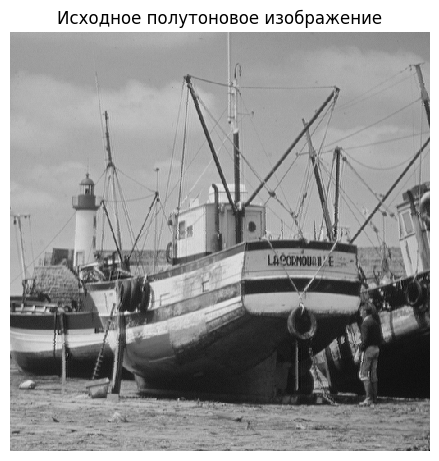

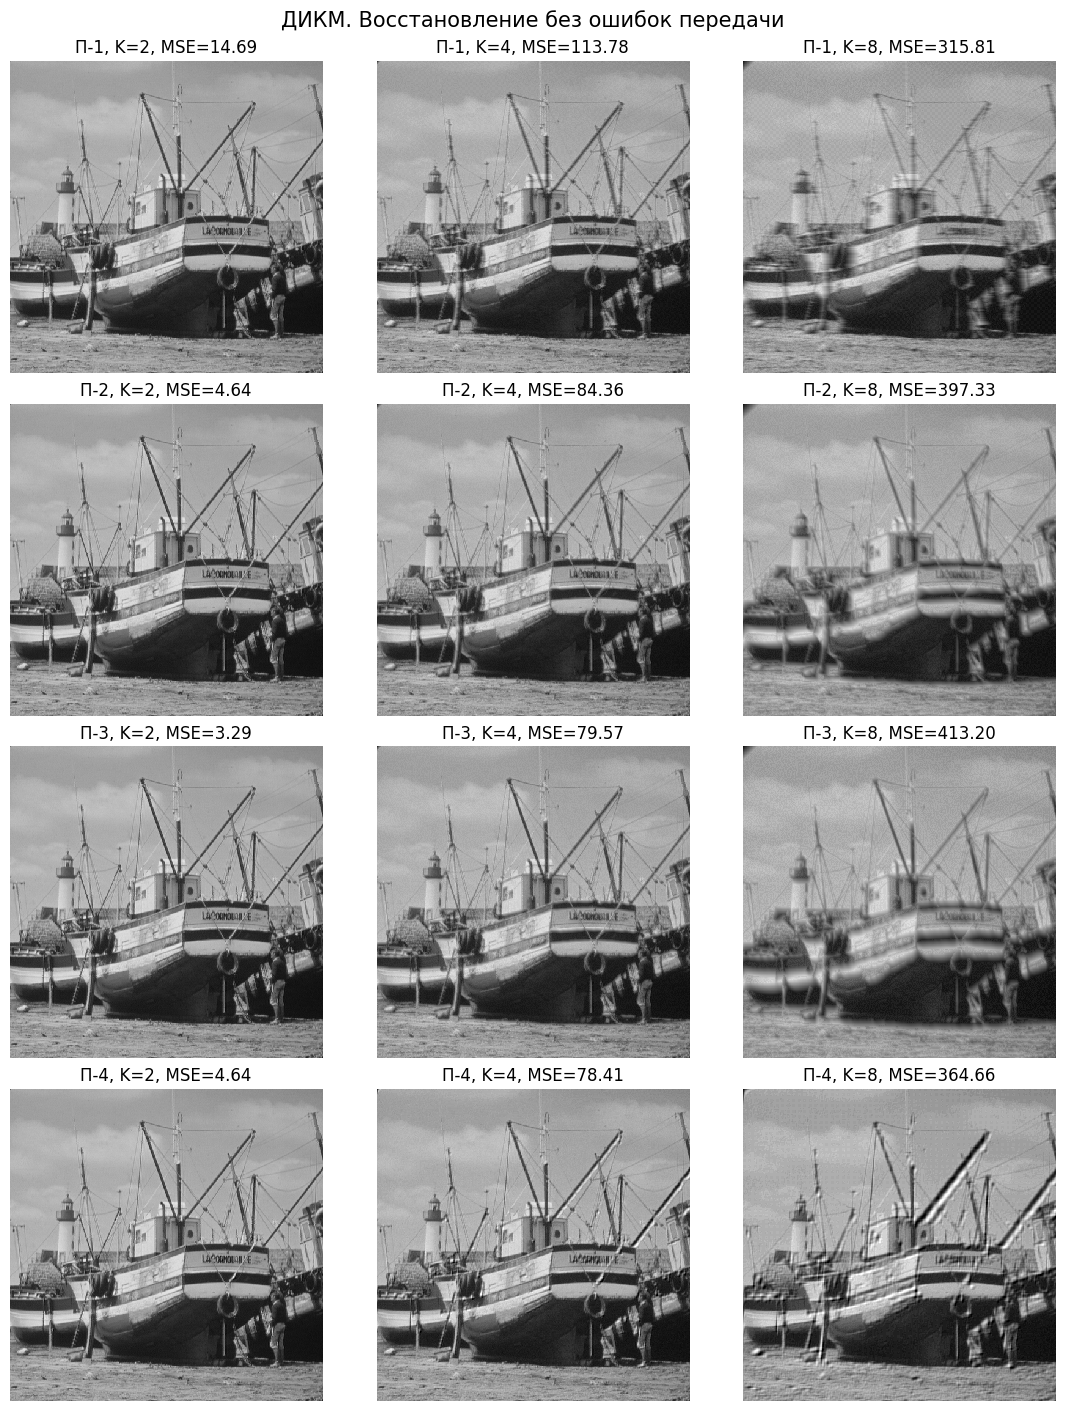

In [7]:
def show_frame(ax, frame, title):
    ax.imshow(frame, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    ax.set_title(title)
    ax.axis('off')


fig, ax = plt.subplots(figsize=(4.5, 4.5), layout='constrained')
show_frame(ax, source, 'Исходное полутоновое изображение')
plt.show()

fig, axes = plt.subplots(4, 3, figsize=(11, 14), layout='constrained')
fig.suptitle('ДИКМ. Восстановление без ошибок передачи', fontsize=15)
for row, name in enumerate(PREDICTORS):
    for col, ratio in enumerate(RATES):
        result = quality_results[name, ratio]
        show_frame(axes[row, col], result['restored'],
                   f'{name}, K={ratio}, MSE={result["mse"]:.2f}')
plt.show()

## 5. Задание 2. Ошибка одного бита при $K_{\rm сж}=8$

Используется однобитный поток. Каждый его бит соответствует ровно одному
пикселю, поэтому позиция сбоя однозначно переводится в координаты.
Полезная нагрузка делится на четыре четверти. Для каждой четверти берётся
позиция около её середины со сдвигом на полстроки, чтобы на кадре обычного
размера сбой пришёлся внутрь строки. В каждом опыте копируется исходный
битовый поток. Смещения одинаковы для всех предсказателей.

Карта ошибки равна разности выхода после сбоя и выхода **без сбоя**.
Для сравнения используются MSE этой разности, её максимальный модуль и число
изменённых пикселей. Наиболее помехоустойчивым считаем предсказатель с
наименьшей средней MSE по четырём позициям. Число изменённых пикселей
характеризует пространственный охват, а не величину отклонений.

In [8]:
edges = [q * source.size // 4 for q in range(5)]
positions = [
    min((start + stop) // 2 + width // 2, stop - 1)
    for start, stop in zip(edges, edges[1:])
]
noise_results = {}
for name, coefficients in PREDICTORS.items():
    clean = quality_results[name, 8]
    for quarter, position in enumerate(positions, start=1):
        damaged = flip_bit(clean['payload'], position, source.size)
        altered = unpack_indices(damaged, source.shape, 1)
        original = unpack_indices(clean['payload'], source.shape, 1)
        np.testing.assert_array_equal(np.flatnonzero(altered != original), [position])
        restored = decode(damaged, source.shape, coefficients, 1, clean['levels'])
        difference = restored - clean['restored']
        assert not np.any(difference.ravel()[:position])
        changed = np.abs(difference) > 1e-9
        mse, maximum = errors(clean['restored'], restored)
        rows, cols = np.nonzero(changed)
        noise_results[name, quarter] = dict(
            restored=restored, difference=difference, mse=mse, maximum=maximum,
            count=int(changed.sum()), rows=len(np.unique(rows)), cols=len(np.unique(cols)),
            position=position, center=divmod(position, width),
        )

lines = ['| Предсказатель | Четверть | Бит (с нуля) | Строка, столбец | MSE сбоя | '
         'Макс. ошибка | Затронуто пикселей | Строк охвачено |',
         '|---|---:|---:|---|---:|---:|---:|---:|']
for (name, quarter), r in noise_results.items():
    lines.append(f'| {name} | {quarter} | {r["position"]} | {r["center"]} | '
                 f'{r["mse"]:.5f} | {r["maximum"]:.3f} | {r["count"]} | {r["rows"]} |')
display(Markdown('\n'.join(lines)))

mean_damage = {p: float(np.mean([noise_results[p, q]['mse'] for q in range(1, 5)]))
               for p in PREDICTORS}
overall_robustness = min(mean_damage, key=mean_damage.get)
assert len(quality_results) == 12 and len(noise_results) == 16
print('Средняя MSE сбоя по четырём позициям:', {p: round(v, 5) for p, v in mean_damage.items()})
print('Наиболее помехоустойчивый по этому критерию:', overall_robustness)

| Предсказатель | Четверть | Бит (с нуля) | Строка, столбец | MSE сбоя | Макс. ошибка | Затронуто пикселей | Строк охвачено |
|---|---:|---:|---|---:|---:|---:|---:|
| П-1 | 1 | 33024 | (64, 256) | 0.22513 | 15.183 | 256 | 1 |
| П-1 | 2 | 98560 | (192, 256) | 0.22513 | 15.183 | 256 | 1 |
| П-1 | 3 | 164096 | (320, 256) | 0.22513 | 15.183 | 256 | 1 |
| П-1 | 4 | 229632 | (448, 256) | 0.22513 | 15.183 | 256 | 1 |
| П-2 | 1 | 33024 | (64, 256) | 0.01254 | 11.348 | 49358 | 417 |
| П-2 | 2 | 98560 | (192, 256) | 0.01254 | 11.348 | 45615 | 320 |
| П-2 | 3 | 164096 | (320, 256) | 0.01085 | 11.348 | 29862 | 192 |
| П-2 | 4 | 229632 | (448, 256) | 0.00626 | 11.348 | 6400 | 64 |
| П-3 | 1 | 33024 | (64, 256) | 0.01250 | 12.693 | 82663 | 448 |
| П-3 | 2 | 98560 | (192, 256) | 0.01059 | 12.693 | 51013 | 320 |
| П-3 | 3 | 164096 | (320, 256) | 0.00823 | 12.693 | 23882 | 192 |
| П-3 | 4 | 229632 | (448, 256) | 0.00480 | 12.693 | 4664 | 64 |
| П-4 | 1 | 33024 | (64, 256) | 887.76171 | 242.534 | 112020 | 448 |
| П-4 | 2 | 98560 | (192, 256) | 751.14943 | 238.048 | 79394 | 320 |
| П-4 | 3 | 164096 | (320, 256) | 75.91209 | 52.678 | 45641 | 192 |
| П-4 | 4 | 229632 | (448, 256) | 5.58106 | 10.889 | 12369 | 64 |

Средняя MSE сбоя по четырём позициям: {'П-1': 0.22513, 'П-2': 0.01055, 'П-3': 0.00903, 'П-4': 430.10107}
Наиболее помехоустойчивый по этому критерию: П-3


### Восстановления после сбоя и контрастированные карты разности

В первой панели каждого ряда показан кадр без сбоя. Для каждой четверти
верхний ряд показывает восстановление после инверсии, нижний — знаковую
разность относительно кадра без сбоя. Крест отмечает позицию инверсии.
Для карт выбрана шкала до 95-го процентиля модулей ненулевых ошибок
конкретного опыта, чтобы слабые следы были видимы. За пределами шкалы
цвет насыщается. Однострочный след подчёркнут цветными точками, чтобы
он оставался виден при уменьшении рисунка. Численные показатели
рассчитываются по исходной разности. У каждой карты подписан её диапазон.

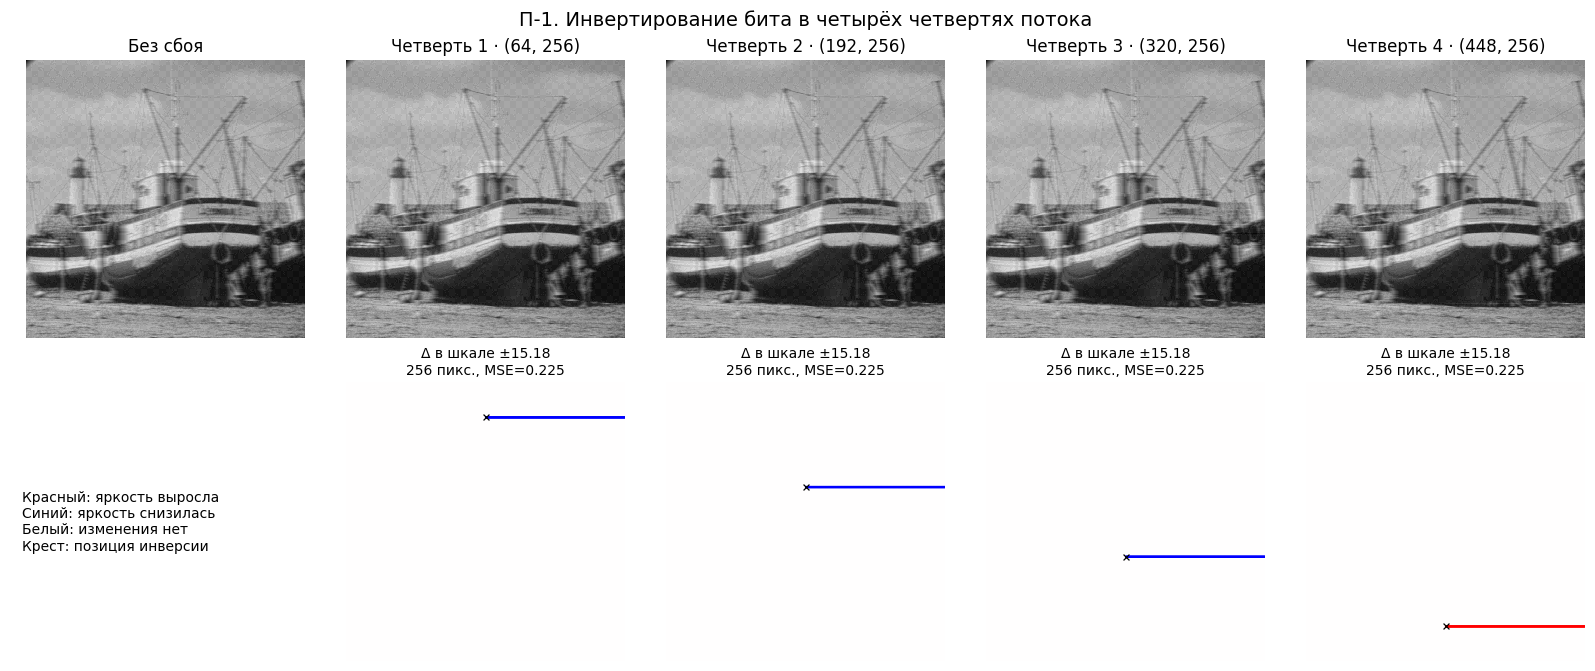

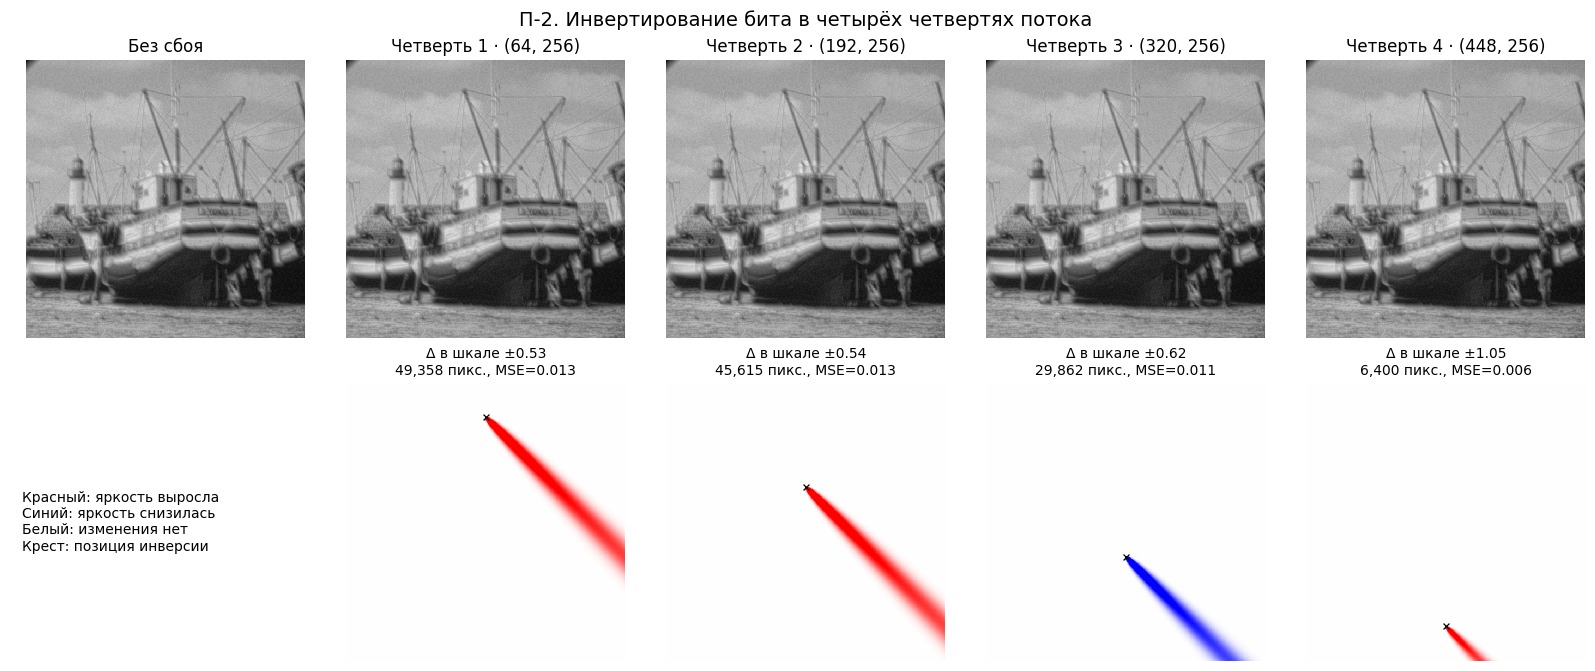

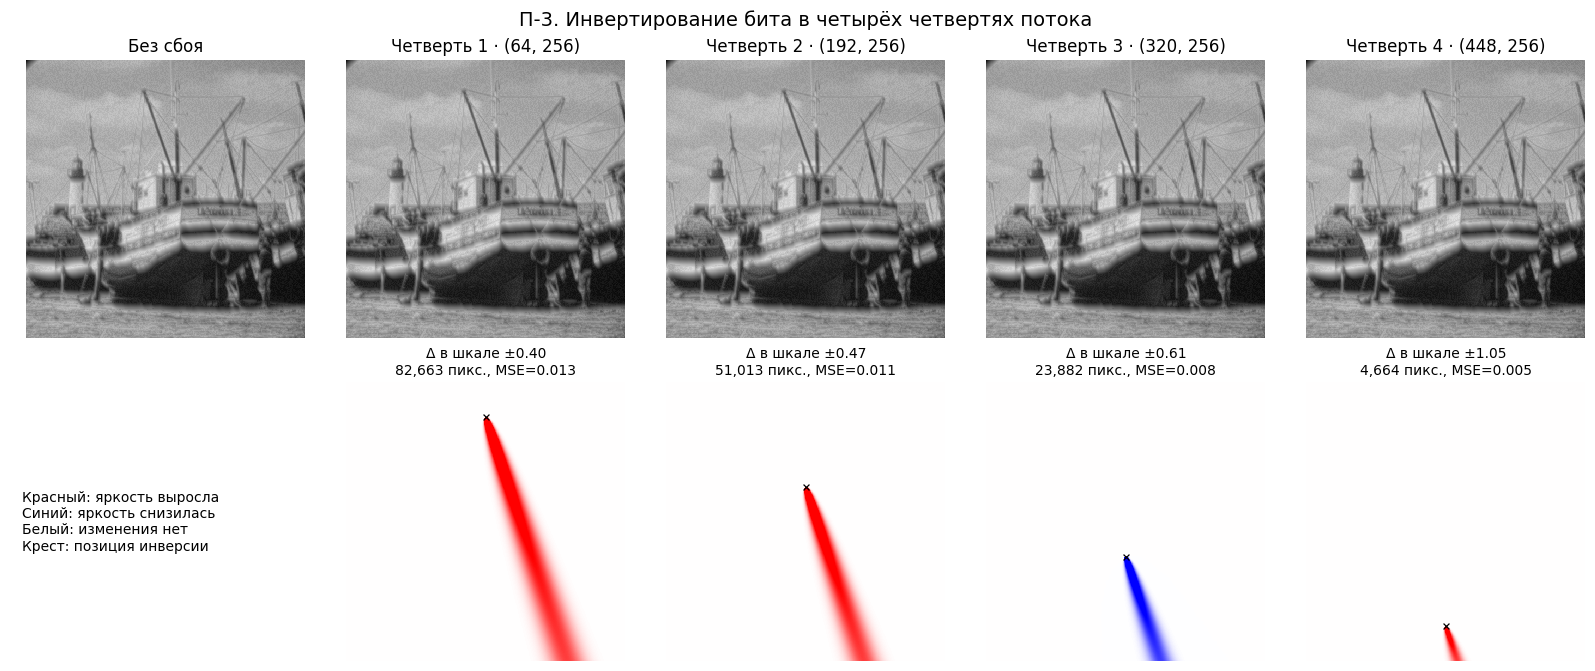

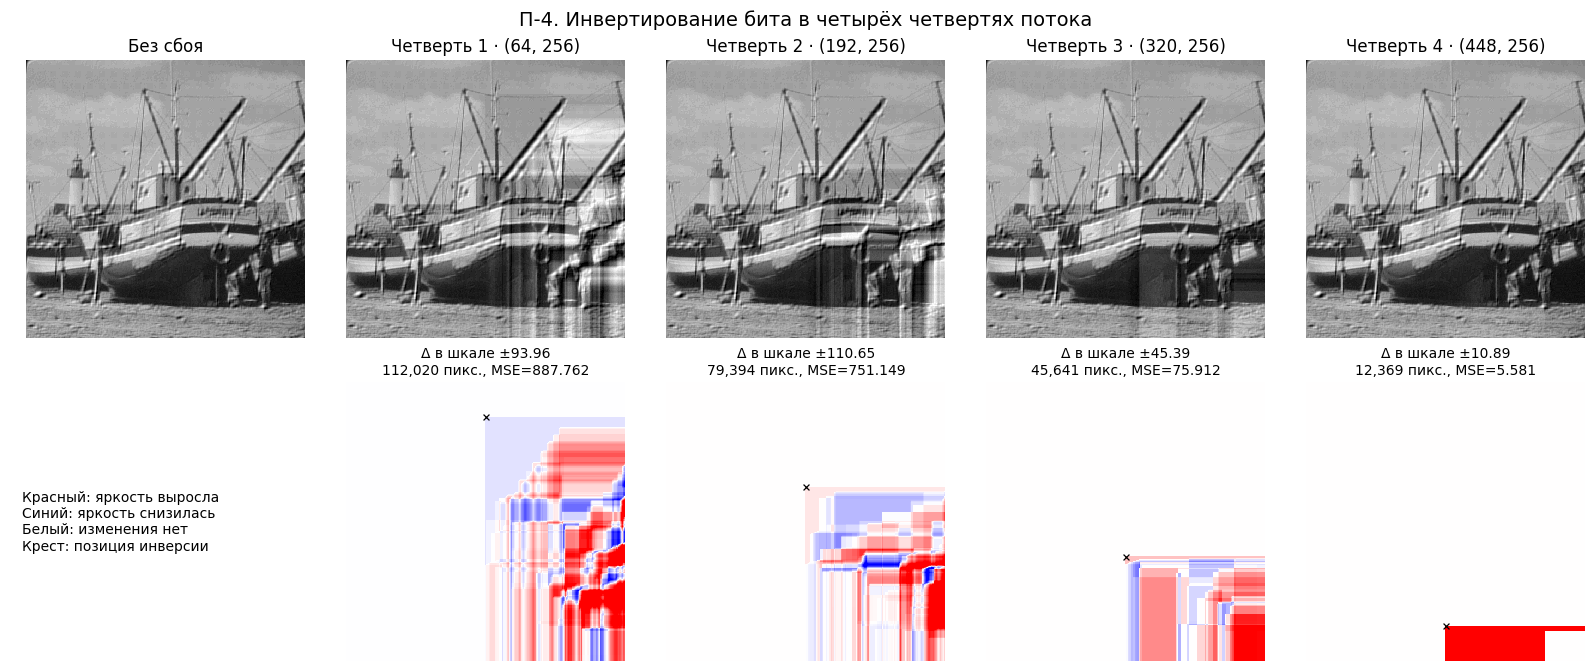

In [9]:
for name in PREDICTORS:
    fig, axes = plt.subplots(2, 5, figsize=(16, 6.6), layout='constrained')
    fig.suptitle(f'{name}. Инвертирование бита в четырёх четвертях потока', fontsize=14)
    show_frame(axes[0, 0], quality_results[name, 8]['restored'], 'Без сбоя')
    axes[1, 0].axis('off')
    axes[1, 0].text(.04, .5, 'Красный: яркость выросла\nСиний: яркость снизилась\n'
                           'Белый: изменения нет\nКрест: позиция инверсии',
                    transform=axes[1, 0].transAxes, va='center', fontsize=10)
    for quarter in range(1, 5):
        result = noise_results[name, quarter]
        row, col = result['center']
        show_frame(axes[0, quarter], result['restored'], f'Четверть {quarter} · ({row}, {col})')
        difference = result['difference']
        absolute = np.abs(difference)
        nonzero = absolute[absolute > 1e-9]
        limit = float(np.percentile(nonzero, 95)) if nonzero.size else 1.
        error_ax = axes[1, quarter]
        error_ax.imshow(difference, cmap='bwr', vmin=-limit, vmax=limit, interpolation='nearest')
        if result['rows'] == 1:
            trace_rows, trace_cols = np.nonzero(absolute > 1e-9)
            error_ax.scatter(trace_cols, trace_rows, c=difference[trace_rows, trace_cols],
                             cmap='bwr', vmin=-limit, vmax=limit, s=3, linewidths=0)
        error_ax.scatter([col], [row], marker='x', color='black', s=18, linewidths=.9)
        error_ax.set_title(f'Δ в шкале ±{limit:.2f}\n{result["count"]:,} пикс., '
                           f'MSE={result["mse"]:.3f}', fontsize=10)
        error_ax.axis('off')
    plt.show()

## 6. Выводы по экспериментам

В таблицах сравниваются только результаты для текущего кадра. Структура
предсказателя определяет возможный путь распространения ошибки, а форма
этого следа зависит от положения сбоя и насыщения восстановленной яркости.

In [10]:
lines = []
for ratio, winner in best_by_rate.items():
    result = quality_results[winner, ratio]
    lines.append(f'- При K = {ratio} минимум у **{winner}**, MSE = {result["mse"]:.3f}.')
lines.append(f'- При выборе одного предсказателя по средней MSE трёх режимов '
             f'лидирует **{overall_quality}** ({mean_quality[overall_quality]:.3f}).')
for name in PREDICTORS:
    values = [quality_results[name, ratio]['mse'] for ratio in RATES]
    comparison = ' → '.join(f'{v:.2f}' for v in values)
    lines.append(f'- {name}, MSE при K = 2, 4, 8: {comparison}.')
display(Markdown('\n'.join(lines)))

lines = [f'**Наименьшая средняя MSE сбоя у {overall_robustness}** '
         f'({mean_damage[overall_robustness]:.5f}).', '',
         '| Предсказатель | Средняя MSE сбоя | Пикселей по четвертям | Строк по четвертям |',
         '|---|---:|---|---|']
for name in PREDICTORS:
    experiments = [noise_results[name, q] for q in range(1, 5)]
    affected = ' / '.join(str(r['count']) for r in experiments)
    row_counts = ' / '.join(str(r['rows']) for r in experiments)
    lines.append(f'| {name} | {mean_damage[name]:.5f} | {affected} | {row_counts} |')
display(Markdown('\n'.join(lines)))

- При K = 2 минимум у **П-3**, MSE = 3.285.
- При K = 4 минимум у **П-4**, MSE = 78.408.
- При K = 8 минимум у **П-1**, MSE = 315.810.
- При выборе одного предсказателя по средней MSE трёх режимов лидирует **П-1** (148.094).
- П-1, MSE при K = 2, 4, 8: 14.69 → 113.78 → 315.81.
- П-2, MSE при K = 2, 4, 8: 4.64 → 84.36 → 397.33.
- П-3, MSE при K = 2, 4, 8: 3.29 → 79.57 → 413.20.
- П-4, MSE при K = 2, 4, 8: 4.64 → 78.41 → 364.66.

**Наименьшая средняя MSE сбоя у П-3** (0.00903).

| Предсказатель | Средняя MSE сбоя | Пикселей по четвертям | Строк по четвертям |
|---|---:|---|---|
| П-1 | 0.22513 | 256 / 256 / 256 / 256 | 1 / 1 / 1 / 1 |
| П-2 | 0.01055 | 49358 / 45615 / 29862 / 6400 | 417 / 320 / 192 / 64 |
| П-3 | 0.00903 | 82663 / 51013 / 23882 / 4664 | 448 / 320 / 192 / 64 |
| П-4 | 430.10107 | 112020 / 79394 / 45641 / 12369 | 448 / 320 / 192 / 64 |

### Интерпретация результатов на кадре 04_boat.tif

**Точность.** Для всех предсказателей MSE выросла при переходе
от 16 к 4, а затем к 2 уровням квантования. При $K_{\rm сж}=2$
П-3 дал наименьшую MSE. В окрестностях с плавной яркостью оценка по
четырём соседям учитывает сразу несколько направлений, а 16 уровней
позволяют достаточно точно передавать поправку к этой оценке.
При $K_{\rm сж}=4$ минимальная ошибка у П-4. Его оценка $L+U-UL$
воспроизводит линейное изменение яркости во внутренней части кадра.
При одном бите сохраняется только индикатор знака и используются
поправки фиксированного модуля. На этом кадре П-1 с предсказанием
по одному соседу дал меньшую ошибку, а у П-2 и П-3 на рисунках
сильнее заметна потеря резкости. Среди трёх режимов при равном весе
выигрывает П-1 по средней MSE.

**Распространение сбоя.** Все искажения начинаются у отмеченного бита.
Отсчёты, восстановленные до него, совпадают с декодированием без сбоя.
Сбой в четвёртой четверти оставляет меньше строк для распространения,
чем сбой в первой. Для П-1 при выбранном столбце это ограничение
не меняет длину следа.

- **П-1.** Предсказание использует левый пиксель, поэтому ошибка
  передаётся вправо до конца текущей строки. На данном кадре
  во всех четырёх опытах изменилось 256 пикселей. Модуль ошибки
  составил около 15,18 на всём следе.
- **П-2.** Среднее левого и верхнего соседей передаёт ошибку вправо
  и вниз. На карте видна диагональная полоса с затухающим отклонением.
- **П-3.** Четыре соседа распределяют ошибку по нескольким
  направлениям. На карте заметен более вертикальный след. Части
  изображения могут изменяться на очень малую величину, поэтому
  при большой площади следа средняя MSE сбоя у П-3 минимальна
  ($0{,}00903$).
- **П-4.** Единичные веса и вычитание верхнего левого отсчёта
  допускают сложение вкладов ошибки по модулю. При первом сбое
  максимальное отклонение достигло 242,53. На картах видны
  протяжённые области разного знака. Их форма зависит от позиции
  сбоя и от того, где восстановленная яркость достигла 0 или 255.

По средней мощности искажения от сбоя выигрывает П-3. По числу
затронутых пикселей в этих четырёх опытах выигрывает П-1. Оба вывода
относятся к выбранному кадру, шкале Макса и указанным позициям битов.